In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Flatten, Dense
from sklearn.preprocessing import LabelEncoder
print("done")

done


In [11]:
#load dataset
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print(train_data.head())

   label  pixel1  pixel2  pixel3  pixel4  pixel5  ...  pixel779  pixel780  pixel781  pixel782  pixel783  pixel784
0      3     107     118     127     134     139  ...       206       206       206       204       203       202
1      6     155     157     156     156     156  ...        94       163       175       103       135       149
2      2     187     188     188     187     187  ...       198       199       198       195       194       195
3      2     211     211     212     212     211  ...       230       226       225       222       229       163
4     13     164     167     170     172     176  ...       133       163       157       163       164       179

[5 rows x 785 columns]


In [12]:
#separate
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [13]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [14]:
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

In [19]:
#define FNN
#layers, input shape, activation func
model = Sequential([
    Flatten(input_shape=(784,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(24, activation='softmax')  #will return probabilities summing to 1, whichevr probability is highest, will be the label
])

In [20]:
#compile
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("done")

done


In [21]:
#train
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.2091 - loss: 2.7672 - val_accuracy: 0.2068 - val_loss: 2.4558
Epoch 2/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4373 - loss: 1.8250 - val_accuracy: 0.2924 - val_loss: 2.1678
Epoch 3/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5606 - loss: 1.3889 - val_accuracy: 0.5466 - val_loss: 1.3068
Epoch 4/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6427 - loss: 1.1121 - val_accuracy: 0.3227 - val_loss: 2.4918
Epoch 5/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7024 - loss: 0.9306 - val_accuracy: 0.5830 - val_loss: 1.1654
Epoch 6/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7544 - loss: 0.7740 - val_accuracy: 0.7833 - val_loss: 0.7105
Epoch 7/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7989 - loss: 0.6464 - val_accuracy: 0.5175 - val_loss: 1.6359
Epoch 8/20
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8301 - loss: 0.5399 - val_accuracy: 0.

In [22]:
#evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test loss: ", test_loss)
print("Test accuracy: ", test_accuracy*100, "%")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7547 - loss: 1.0145
Test loss:  1.0145362615585327
Test accuracy:  75.47406554222107 %


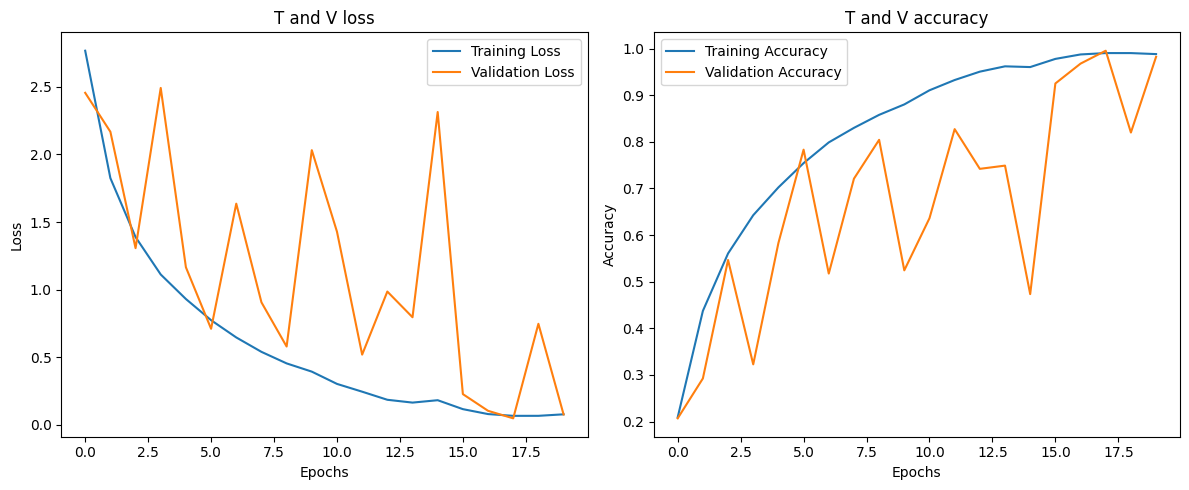

In [23]:
#plotting
plt.figure(figsize=(12, 5))

#Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation Loss")
plt.title("T and V loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

#Loss
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = "Training Accuracy")
plt.plot(history.history['val_accuracy'], label = "Validation Accuracy")
plt.title("T and V accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()